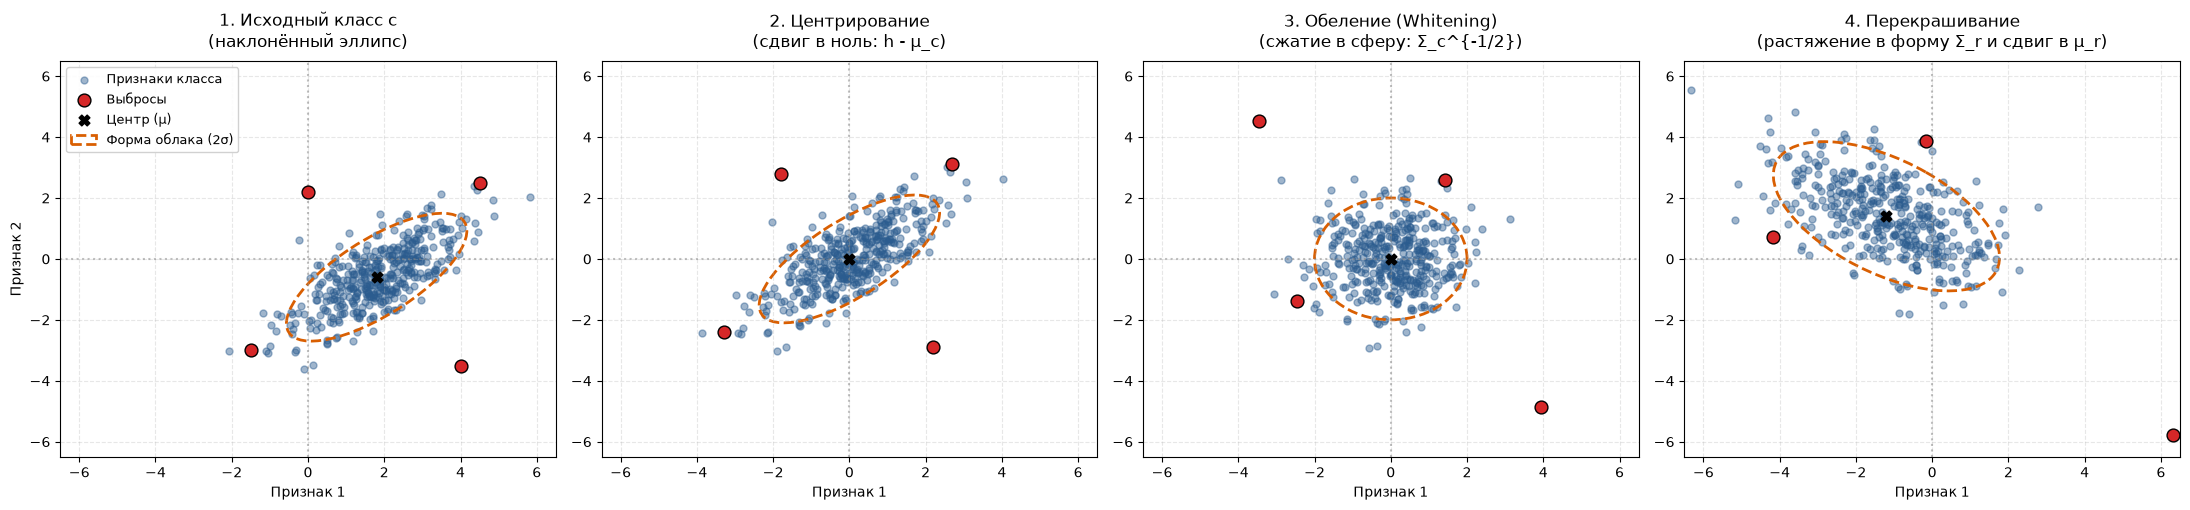

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import scipy.linalg

# 1. Фиксация сида и генерация синтетических признаков
np.random.seed(42)
n_samples = 400

# Параметры забываемого класса c (вытянуто под углом ~45 градусов)
mu_c = np.array([1.8, -0.6])
cov_c = np.array([[1.4, 0.9], 
                  [0.9, 1.1]])

# Нормальные точки класса c
X_normal = np.random.multivariate_normal(mu_c, cov_c, size=n_samples)

# Искусственные выбросы (точки на периферии признакового пространства)
outliers = np.array([
    [4.5, 2.5],   # далеко по главной оси
    [-1.5, -3.0], # далеко против главной оси
    [4.0, -3.5],  # перпендикулярный выброс
    [0.0, 2.2]    # аномальное соотношение признаков
])

X = np.vstack([X_normal, outliers])
is_outlier = np.zeros(len(X), dtype=bool)
is_outlier[-len(outliers):] = True

# Параметры целевой смеси r (другой центр, обратный наклон и иной масштаб)
mu_r = np.array([-1.2, 1.4])
cov_r = np.array([[2.2, -1.0], 
                  [-1.0, 1.5]])

# 2. Вычисление операторов транспорта
# Матричные корни (симметричные, эрмитовы)
Sigma_c_sqrt = scipy.linalg.sqrtm(cov_c).real
Sigma_c_inv_sqrt = scipy.linalg.inv(Sigma_c_sqrt)
Sigma_r_sqrt = scipy.linalg.sqrtm(cov_r).real

# Пошаговая трансформация (векторы строк X: X @ A.T эквивалентно A @ x)
# Шаг 1: Исходные данные
X_step1 = X.copy()

# Шаг 2: Центрирование (h - mu_c)
X_step2 = X - mu_c

# Шаг 3: Обеление / Whitening (Sigma_c^{-1/2} * (h - mu_c))
X_step3 = X_step2 @ Sigma_c_inv_sqrt.T

# Шаг 4: Перекрашивание и сдвиг в mu_r
X_step4 = mu_r + X_step3 @ Sigma_r_sqrt.T


# Вспомогательная функция для отрисовки эллипса ковариации (2-сигма)
def draw_cov_ellipse(ax, mean, cov, color, label):
    vals, vecs = np.linalg.eigh(cov)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]
    theta = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
    # 2 сигмы покрывают ~95% нормального распределения
    width, height = 2 * 2 * np.sqrt(np.maximum(vals, 1e-8))
    ellipse = Ellipse(xy=mean, width=width, height=height, angle=theta,
                      edgecolor=color, facecolor='none', lw=2, linestyle='--', label=label)
    ax.add_patch(ellipse)


# 3. Отрисовка 4 шагов
fig, axes = plt.subplots(1, 4, figsize=(22, 5.2))
steps_data = [
    (X_step1, mu_c, cov_c, "1. Исходный класс c\n(наклонённый эллипс)"),
    (X_step2, np.array([0.0, 0.0]), cov_c, "2. Центрирование\n(сдвиг в ноль: h - μ_c)"),
    (X_step3, np.array([0.0, 0.0]), np.eye(2), "3. Обеление (Whitening)\n(сжатие в сферу: Σ_c^{-1/2})"),
    (X_step4, mu_r, cov_r, "4. Перекрашивание\n(растяжение в форму Σ_r и сдвиг в μ_r)")
]

for idx, (data, mean, cov, title) in enumerate(steps_data):
    ax = axes[idx]
    
    # Сетка и оси координат
    ax.axhline(0, color='gray', linestyle=':', alpha=0.5)
    ax.axvline(0, color='gray', linestyle=':', alpha=0.5)
    
    # Обычные точки
    ax.scatter(data[~is_outlier, 0], data[~is_outlier, 1], 
               color='#2b5c8f', alpha=0.45, s=25, label='Признаки класса' if idx == 0 else "")
    
    # Выбросы
    ax.scatter(data[is_outlier, 0], data[is_outlier, 1], 
               color='#d62728', edgecolors='black', s=85, zorder=5, 
               label='Выбросы' if idx == 0 else "")
    
    # Центр облака
    ax.scatter(mean[0], mean[1], color='black', s=60, marker='X', zorder=6,
               label='Центр (μ)' if idx == 0 else "")
    
    # Контур ковариации
    draw_cov_ellipse(ax, mean, cov, color='#d95f02', label='Форма облака (2σ)' if idx == 0 else "")
    
    ax.set_title(title, fontsize=12, pad=10)
    ax.set_xlabel("Признак 1")
    if idx == 0:
        ax.set_ylabel("Признак 2")
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.set_xlim(-6.5, 6.5)
    ax.set_ylim(-6.5, 6.5)

axes[0].legend(loc='upper left', framealpha=0.9, fontsize=9)
plt.tight_layout()
plt.show()